### Trabajo Práctico Final: Airbnb Price
#### Notebook N°2: Machine Learning

El objetivo de esta notebook es desarrollar modelos de Machine Learning capaces de predecir el
precio por noche de alojamientos de Airbnb en Estados Unidos, utilizando las características disponibles en el dataset.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

eda = pd.read_csv("airbnb_us.csv")

print("Dimensiones:", eda.shape)
eda.head()


Dimensiones: (19309, 29)


,id,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,city,...,longitude,name,neighbourhood,number_of_reviews,review_scores_rating,thumbnail_url,zipcode,bedrooms,beds,price
0,13418779,House,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",Ki...",4,1.0,Real Bed,flexible,True,SF,...,-122.431619,Beautiful Flat in the Heart of SF!,Lower Haight,0,NaN,https://a0.muscache.com/im/pictures/72208dad-9...,94117.0,2.0,2.0,750.0
1,3808709,Apartment,Entire home/apt,"{TV,Internet,""Wireless Internet"",""Air conditio...",2,1.0,Real Bed,moderate,True,DC,...,-77.034596,Great studio in midtown DC,Columbia Heights,4,40.0,NaN,20009,0.0,1.0,115.0
2,12422935,Apartment,Private room,"{TV,""Wireless Internet"",Heating,""Smoke detecto...",2,1.0,Real Bed,strict,True,SF,...,-122.429526,Comfort Suite San Francisco,Noe Valley,3,100.0,https://a0.muscache.com/im/pictures/82509143-4...,94131,1.0,1.0,85.0
3,180792,House,Private room,"{TV,""Cable TV"",""Wireless Internet"",""Pets live ...",2,1.0,Real Bed,moderate,True,SF,...,-122.501095,Cozy Garden Studio - Private Entry,Richmond District,159,99.0,https://a0.muscache.com/im/pictures/0ed6c128-7...,94121,1.0,1.0,120.0
4,2658946,Apartment,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",""A...",6,1.5,Real Bed,strict,True,DC,...,-77.031189,Charming 2 bdrm in trendy U/14th streets w/par...,U Street Corridor,13,89.0,NaN,20009,2.0,3.0,200.0


In [3]:
variables = [
    'property_type',
    'room_type',
    'accommodates',
    'bathrooms',
    'bed_type',
    'cancellation_policy',
    'cleaning_fee',
    'city',
    'host_has_profile_pic',
    'host_identity_verified',
    'host_response_rate',
    'instant_bookable',
    'latitude',
    'longitude',
    'number_of_reviews',
    'review_scores_rating',
    'bedrooms',
    'beds'
]

X = eda[variables].copy()
y = eda['price'].copy()

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (19309, 18)
Dimensiones de y: (19309,)


In [4]:
X['host_response_rate'] = (
    X['host_response_rate']
    .str.replace('%', '', regex=False)
    .astype(float)
)

print(X['host_response_rate'].head())

0      NaN
1    100.0
2    100.0
3    100.0
4    100.0
Name: host_response_rate, dtype: float64


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (15447, 18)
Datos de prueba: (3862, 18)


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

variables_numericas = [
    'accommodates',
    'bathrooms',
    'host_response_rate',
    'latitude',
    'longitude',
    'number_of_reviews',
    'review_scores_rating',
    'bedrooms',
    'beds'
]

variables_categoricas = [
    'property_type',
    'room_type',
    'bed_type',
    'cancellation_policy',
    'city',
    'cleaning_fee',
    'host_has_profile_pic',
    'host_identity_verified',
    'instant_bookable'
]

preprocesamiento_numerico = Pipeline(steps=[
    ('imputacion', SimpleImputer(strategy='median')),
    ('escalado', StandardScaler())
])

preprocesamiento_categorico = Pipeline(steps=[
    ('imputacion', SimpleImputer(strategy='most_frequent')),
    ('codificacion', OneHotEncoder(handle_unknown='ignore'))
])

preprocesamiento = ColumnTransformer(transformers=[
    ('numericas', preprocesamiento_numerico, variables_numericas),
    ('categoricas', preprocesamiento_categorico, variables_categoricas)
])

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [9]:
modelo_regresion = Pipeline(steps=[
    ('preprocesamiento', preprocesamiento),
    ('modelo', LinearRegression())
])

modelo_random_forest = Pipeline(steps=[
    ('preprocesamiento', preprocesamiento),
    ('modelo', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

In [10]:
modelo_regresion.fit(X_train, y_train)

modelo_random_forest.fit(X_train, y_train)

print("Modelos entrenados correctamente")

Modelos entrenados correctamente


In [11]:
pred_regresion = modelo_regresion.predict(X_test)

pred_random_forest = modelo_random_forest.predict(X_test)

In [12]:
resultados = []

for nombre, predicciones in [
    ('Regresión Lineal', pred_regresion),
    ('Random Forest', pred_random_forest)
]:
    mae = mean_absolute_error(y_test, predicciones)
    rmse = np.sqrt(mean_squared_error(y_test, predicciones))
    r2 = r2_score(y_test, predicciones)

    resultados.append({
        'Modelo': nombre,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

tabla_resultados = pd.DataFrame(resultados)

display(tabla_resultados.round(3))

,Modelo,MAE,RMSE,R2
0,Regresión Lineal,96.568,173.042,0.355
1,Random Forest,77.592,158.479,0.459


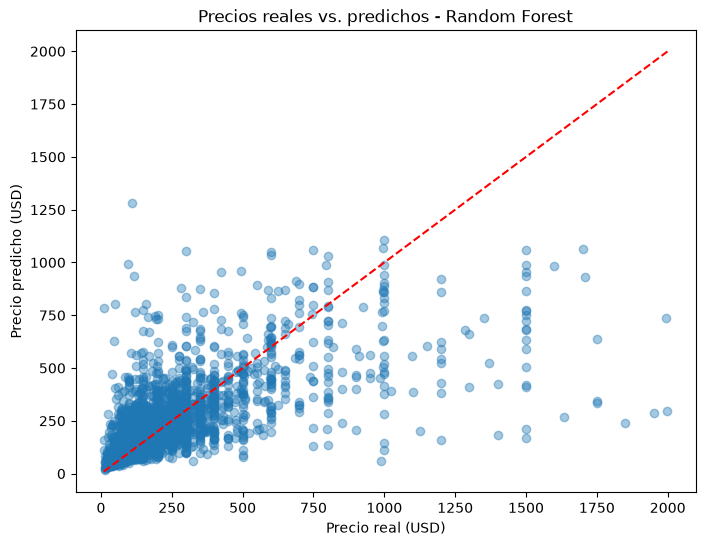

In [13]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, pred_random_forest, alpha=0.4)

plt.xlabel('Precio real (USD)')
plt.ylabel('Precio predicho (USD)')
plt.title('Precios reales vs. predichos - Random Forest')

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()

In [15]:
from sklearn.decomposition import PCA

preprocesamiento_categorico_pca = Pipeline(steps=[
    ('imputacion', SimpleImputer(strategy='most_frequent')),
    ('codificacion', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

preprocesamiento_pca = ColumnTransformer(transformers=[
    ('numericas', preprocesamiento_numerico, variables_numericas),
    ('categoricas', preprocesamiento_categorico_pca, variables_categoricas)
])

In [16]:
modelo_pca_regresion = Pipeline(steps=[
    ('preprocesamiento', preprocesamiento_pca),
    ('pca', PCA(n_components=0.95)),
    ('modelo', LinearRegression())
])

modelo_pca_random_forest = Pipeline(steps=[
    ('preprocesamiento', preprocesamiento_pca),
    ('pca', PCA(n_components=0.95)),
    ('modelo', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

In [22]:
resultados_pca = []

for nombre, predicciones in [
    ('Regresión Lineal + PCA', pred_pca_regresion),
    ('Random Forest + PCA', pred_pca_random_forest)
]:
    mae = mean_absolute_error(y_test, predicciones)
    rmse = np.sqrt(mean_squared_error(y_test, predicciones))
    r2 = r2_score(y_test, predicciones)

    resultados_pca.append({
        'Modelo': nombre,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

tabla_pca = pd.DataFrame(resultados_pca)

display(tabla_pca.round(3))

,Modelo,MAE,RMSE,R2
0,Regresión Lineal + PCA,98.905,175.065,0.340
1,Random Forest + PCA,86.267,162.004,0.435


In [21]:
pred_pca_regresion = modelo_pca_regresion.predict(X_test)

pred_pca_random_forest = modelo_pca_random_forest.predict(X_test)

print("Predicciones con PCA realizadas correctamente")

Predicciones con PCA realizadas correctamente


In [19]:
print(
    "Cantidad de componentes utilizadas:",
    modelo_pca_regresion.named_steps['pca'].n_components_
)

print(
    "Varianza explicada:",
    modelo_pca_regresion.named_steps['pca'].explained_variance_ratio_.sum()
)

Cantidad de componentes utilizadas: 15
Varianza explicada: 0.9502865983713865


In [23]:
comparacion_final = pd.concat(
    [tabla_resultados, tabla_pca],
    ignore_index=True
)

display(comparacion_final.round(3))

,Modelo,MAE,RMSE,R2
0,Regresión Lineal,96.568,173.042,0.355
1,Random Forest,77.592,158.479,0.459
2,Regresión Lineal + PCA,98.905,175.065,0.340
3,Random Forest + PCA,86.267,162.004,0.435


In [ ]:
### Conclusión de la comparación de modelos con PCA

Al comparar los modelos originales con aquellos que incorporan PCA, se observa que la reducción de dimensionalidad no produjo una mejora en el rendimiento.
En ambos casos, los valores de MAE y RMSE aumentaron, mientras que el coeficiente R² disminuyó.
El modelo que obtuvo los mejores resultados fue **Random Forest sin PCA**, con un MAE de 77.592, un RMSE de 158.479 y un R² de 0.459.
Por lo tanto, para este conjunto de datos, la aplicación de PCA no mejoró la capacidad predictiva de los modelos evaluados.
que PCA no haya mejorado los resultados no significa que esté mal aplicado. 
Significa que, con la configuración utilizada, conservar las variables originales produjo mejores predicciones.